# scorer-minutes: convert wall-clock budgets between GPUs, and read agent scores with their noise

Companion notebook of the paper *Scorer-minutes: hardware-normalized, noise-aware evaluation of coding agents under
wall-clock budgets*. It (1) installs the toolkit, (2) shows on synthetic logs that `calibrate` and `timing` recover known
speeds, and (3) rebuilds the paper's tables and figures from the released aggregates (`data/`). No GPU needed.

In [1]:
import os, subprocess, sys
REPO_URL = "https://github.com/akanksha28pathak/gemma-4-developer-agent"
HERE, DATA = None, None
if os.path.exists("../data"):  # staged copy: tools + data side by side
    HERE, DATA = os.path.abspath(".."), os.path.abspath("../data")
elif os.path.exists("../../../docs/paper/aggregates"):  # inside the main repo: tools/scorer_minutes/notebook
    HERE, DATA = os.path.abspath(".."), os.path.abspath("../../../docs/paper/aggregates")
else:  # Kaggle / Colab: clone the project repo
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "repo"], check=True)
    HERE, DATA = os.path.abspath("repo/tools/scorer_minutes"), os.path.abspath("repo/docs/paper/aggregates")
# standard library only: running from the source tree needs no install (pip install HERE also works)
os.environ["PYTHONPATH"] = os.path.join(HERE, "src") + os.pathsep + os.environ.get("PYTHONPATH", "")
CLI = [sys.executable, "-m", "scorer_minutes"]
sys.path.insert(0, os.path.join(HERE, "tests"))
print("data:", os.path.relpath(DATA))

data: ../../../docs/paper/aggregates


## 1. Synthetic check: a fast setup and a slow, shared one

Two setups with known costs per call: a "scorer" (decode 37.5 tokens/s, prefill 2,200 tokens/s, 0.12 s overhead) and a
"dev box" shared by ten sessions (16 tokens/s, 1,100 tokens/s, 0.4 s). `calibrate` reports the factor between
their session speeds (about 2.2: session speed includes prefill and the context slowdown, so it is not exactly
37.5 / 16), and `timing` recovers the per-call costs exactly (c = 0.4, a = 1/1.1, b = 1000/16, d = 0.23).

In [2]:
import tempfile, json, pathlib
from synth import make_session, write_run
tmp = pathlib.Path(tempfile.mkdtemp())
def run(name, **kw):
    sessions = {f"s{i}": make_session(f"s{i}", seed=i, calls=25, **kw) for i in range(12)}
    return str(write_run(tmp / name, sessions, extra_rows=False))
scorer = run("scorer", decode_tok_s=37.5, prefill_tok_s=2200, overhead_s=0.12, ctx_slowdown=0.19)
dev = run("dev", decode_tok_s=16.0, prefill_tok_s=1100, overhead_s=0.40, ctx_slowdown=0.23)
g = "run/**/llm_calls/*.jsonl"
print(subprocess.run(CLI + ["calibrate", dev, "--reference", scorer, "--glob", g, "--cap-scorer-min", "7"],
                     capture_output=True, text=True).stdout[-1500:])
fit = json.loads(subprocess.run(CLI + ["timing", dev, "--glob", g], capture_output=True, text=True).stdout)["fit"]
print("fitted c, a, b, d:", fit["coef"], " R^2", fit["r2"])

{
  "calibration": {
    "sessions": 12,
    "median_tok_s": 14.416,
    "p25_tok_s": 14.365,
    "p75_tok_s": 14.435,
    "scorer_tok_s": 31.901,
    "factor": 2.213,
    "factor_ci95": [
      2.21,
      2.221
    ],
    "cap_scorer_min": 7.0,
    "cap_wall_min": 15.49
  },
  "reference": {
    "sessions": 12,
    "median_tok_s": 31.901
  },
  "input": {
    "files": 12,
    "records": 300,
    "skipped": 0
  },
  "sessions_at_cap": 4
}

fitted c, a, b, d: {'overhead': 0.4, 'new_prompt_k': 0.90909, 'gen_k': 62.5, 'gen_x_ctx_k': 0.23}  R^2 1.0


## 2. Table 4.1: speed by GPU and concurrency (all full runs)

In [3]:
import csv
rows = list(csv.DictReader(open(os.path.join(DATA, "speed_groups.csv"))))
for r in rows:
    print(f"{r['model']:8} {r['gpu']:20} {r['note']:22} x{r['sessions_in_parallel']:>2}  runs {r['runs']:>2}  "
          f"{r['tok_s_median']:>5} tok/s  factor {r['factor_min']}-{r['factor_max']}")
print("full runs:", sum(int(r["runs"]) for r in rows), " sessions:", sum(int(r["sessions"]) for r in rows))

26B-A4B  Kaggle 4x L4                                x 4  runs  1   28.3 tok/s  factor 1.19-1.19
26B-A4B  Kaggle 4x L4         2 servers TP2          x 6  runs  1   22.1 tok/s  factor 1.52-1.52
26B-A4B  Kaggle 4x L4                                x 7  runs  2   14.6 tok/s  factor 2.24-2.4
26B-A4B  Kaggle 4x L4                                x 8  runs  2   22.2 tok/s  factor 1.43-1.64
26B-A4B  Kaggle 4x L4         2 servers TP2          x 8  runs  2   24.2 tok/s  factor 1.39-1.41
31B      A100 80 GB                                  x 5  runs 16   30.5 tok/s  factor 1.01-1.16
31B      A100 80 GB           + LoRA adapter         x 5  runs  1   26.1 tok/s  factor 1.29-1.29
31B      A100 80 GB           parallel attempts      x12  runs  1   16.9 tok/s  factor 1.99-1.99
31B      H100 SXM 80 GB                              x 5  runs  1   52.0 tok/s  factor 0.65-0.65
31B      Kaggle 4x L4                                x 1  runs  2   33.2 tok/s  factor 1.01-1.02
31B      Kaggle 4x L4          

## 3. Table 4.2: the control (one agent, 55 tasks, seven setups) with exact McNemar tests

In [4]:
from math import comb
def mcnemar(b, c):
    n = b + c
    return 1.0 if n == 0 else min(1.0, 2 * sum(comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)
for r in csv.DictReader(open(os.path.join(DATA, "control_43.csv"))):
    p = mcnemar(int(r["scorer_only"]), int(r["run_only"])) if r["mcnemar_p_vs_scorer"] else None
    print(f"{r['setup']:42} f={r['factor']:>5} cap={r['wall_cap_min']:>5} scorer-min={r['scorer_min']:>4} "
          f"solved={r['solved']:>2} timed-out={r['timed_out']:>2} McNemar p={'-' if p is None else round(p, 2)}")

Kaggle 4x L4, 1 session (scorer)           f= 1.02 cap=  7.0 scorer-min= 6.9 solved=19 timed-out=11 McNemar p=-
H100 SXM, 5 sessions, converted            f= 0.65 cap=  4.8 scorer-min= 7.4 solved=19 timed-out=11 McNemar p=1.0
RTX PRO 6000, 5 sessions, converted        f=  0.9 cap=  6.0 scorer-min= 6.7 solved=19 timed-out=15 McNemar p=1.0
L40S, 5 sessions, converted                f= 1.63 cap= 11.7 scorer-min= 7.2 solved=20 timed-out= 7 McNemar p=1.0
Kaggle 4x L4, 10 sessions, converted       f=  2.4 cap= 15.0 scorer-min= 6.3 solved=20 timed-out= 8 McNemar p=1.0
Kaggle 4x L4, 10 sessions, nominal         f= 2.55 cap=  7.0 scorer-min= 2.7 solved=15 timed-out=37 McNemar p=0.22
A100, 5 sessions (earlier reference)       f= 1.08 cap=  7.0 scorer-min= 6.5 solved=17 timed-out=12 McNemar p=0.73


## 4. Section 4.3: fitted per-call timing coefficients

In [5]:
for r in csv.DictReader(open(os.path.join(DATA, "timing_coefs.csv"))):
    print(f"{r['setup']:50} c={r['c_overhead_s']:>5}  a={r['a_s_per_k_prompt']:>5}  b={r['b_s_per_k_gen']:>5}  "
          f"d={r['d_s_per_k_gen_per_k_ctx']:>5}  decode {r['decode_tok_s_0k']}/{r['decode_tok_s_24k']} tok/s")

Kaggle 4x L4, 1 session (scorer)                   c= 0.12  a= 0.46  b= 26.6  d= 0.19  decode 37.5/32.1 tok/s
Kaggle 4x L4, 10 sessions                          c= 0.41  a= 0.89  b= 62.5  d= 0.23  decode 16.1/14.7 tok/s
H100 SXM, 5 sessions                               c= 0.08  a= 0.25  b= 17.0  d= 0.14  decode 58.8/48.9 tok/s
L40S, 5 sessions                                   c= 0.22  a= 0.39  b= 45.5  d= 0.07  decode 22.0/21.2 tok/s
RTX PRO 6000, 5 sessions (v15, held-out)           c= 0.26  a= 0.17  b= 23.5  d= 0.08  decode 42.6/39.5 tok/s
RTX PRO 6000, 5 sessions, + adapter B (held-out)   c= 0.08  a= 0.24  b= 26.3  d= 0.07  decode 38.0/35.6 tok/s


## 5. Section 5: run noise from the repeated-run matrix

The noise pool leaves out `g31_v12e`, whose two runs used different GPUs (so the pool does not depend on the conversion
it is used to judge).

In [6]:
pool = os.path.join(tmp, "noise_pool.csv")
with open(os.path.join(DATA, "noise_long.csv")) as src, open(pool, "w") as dst:
    for i, line in enumerate(src):
        if i == 0 or not line.startswith("g31_v12e,"):
            dst.write(line)
report = os.path.join(tmp, "noise.md")
subprocess.run(CLI + ["noise", pool, "--markdown", report], capture_output=True, text=True, check=True)
print(open(report).read())
print(subprocess.run(CLI + ["draws", "--sd", "1.6", "--score", "9"], capture_output=True, text=True).stdout)

## Runs per config

| Split | Config | n | Runs | Solved per run | Mean | SD | Task-level SD | Flaky tasks |
|---|---|---|---|---|---|---|---|---|
| train55 | g31_refdavis | 55 | 1 | 20 | 20.00 | - | - | 0 |
| val55 | g31_refdavis | 55 | 1 | 17 | 17.00 | - | - | 0 |
| train55 | g31_v12 | 55 | 2 | 20, 19 | 19.50 | 0.71 | 1.58 | 5 |
| train55 | g31_v12b | 55 | 1 | 18 | 18.00 | - | - | 0 |
| val55 | g31_v12b | 55 | 1 | 18 | 18.00 | - | - | 0 |
| train55 | g31_v12d | 55 | 2 | 20, 18 | 19.00 | 1.41 | 1.41 | 4 |
| train55 | g31_v12e_rft | 55 | 1 | 17 | 17.00 | - | - | 0 |
| train55 | g31_v15 | 55 | 2 | 19, 21 | 20.00 | 1.41 | 1.41 | 4 |
| val55 | g31_v15 | 55 | 2 | 18, 20 | 19.00 | 1.41 | 1.73 | 6 |
| train55 | g31_v15_sft | 55 | 1 | 17 | 17.00 | - | - | 0 |
| val55 | g31_v15_sft | 55 | 2 | 20, 21 | 20.50 | 0.71 | 1.58 | 5 |
| train55 | g31_v15d | 55 | 1 | 19 | 19.00 | - | - | 0 |
| train55 | g31_v9c | 55 | 2 | 15, 13 | 14.00 | 1.41 | 1.41 | 4 |
| train55 | g31_v9d | 55 | 2 | 19, 19 | 19.00 

## 6. Figure: per-session speed by setup

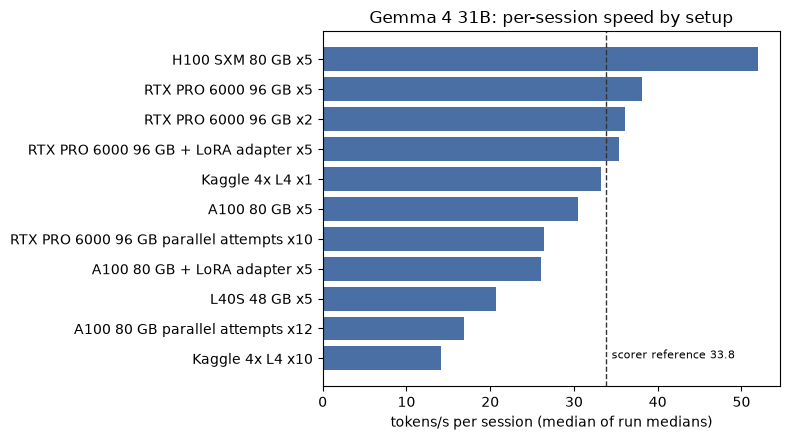

In [7]:
import matplotlib.pyplot as plt
r31 = [r for r in rows if r["model"] == "31B"]
r31.sort(key=lambda r: float(r["tok_s_median"]))
labels = [f"{r['gpu']} {r['note']} x{r['sessions_in_parallel']}".replace("  ", " ") for r in r31]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(labels, [float(r["tok_s_median"]) for r in r31], color="#4a6fa5")
ax.axvline(33.8, color="#333", ls="--", lw=1)
ax.text(34.5, 0, "scorer reference 33.8", fontsize=8)
ax.set_xlabel("tokens/s per session (median of run medians)")
ax.set_title("Gemma 4 31B: per-session speed by setup")
plt.tight_layout(); plt.show()